# Modèle : Extra Trees
Forêt d'arbres **extrêmement aléatoires** : comme Random Forest, mais les seuils de coupure sont tirés au hasard (plus rapide, moins de sur-apprentissage).

Étapes : validation croisée stratifiée → entraînement sur le train → évaluation validation / test → matrice de confusion → SHAP.

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')
import shap

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, ConfusionMatrixDisplay)

# Reproductibilité : même graine partout
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

## 1. Chargement des données préparées (`pretraitement.ipynb`)

In [2]:
data = joblib.load('data_prepared.joblib')
X_train, X_val, X_test = data['X_train'], data['X_val'], data['X_test']
y_train, y_val, y_test = data['y_train'], data['y_val'], data['y_test']

print('Train :', X_train.shape, '| Validation :', X_val.shape, '| Test :', X_test.shape)

Train : (214, 18) | Validation : (42, 18) | Test : (43, 18)


## 2. Modèle
Le préprocesseur (imputation + normalisation + one-hot) est mis **dans un pipeline avec le modèle** :
à chaque entraînement il est ré-appris sur les seules données d'entraînement → pas de fuite de données.

In [3]:
from sklearn.ensemble import ExtraTreesClassifier

model = ExtraTreesClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1)

pipe = Pipeline([('prep', clone(data['preprocessor'])), ('model', model)])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

## 3. Validation croisée stratifiée (5 folds, sur le train)
Le train est découpé en 5 parties en gardant la même proportion de feux dans chacune.
On entraîne 5 fois (4 parties) et on évalue sur la partie restante.

In [4]:
metriques = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall',
             'f1': 'f1', 'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metriques)

cv_scores = pd.DataFrame({m: cv_res[f'test_{m}'] for m in metriques})
cv_scores.agg(['mean', 'std']).T.round(3)

,mean,std
accuracy,0.720,0.054
precision,0.727,0.049
recall,0.869,0.058
f1,0.790,0.039
roc_auc,0.779,0.034
pr_auc,0.832,0.034


## 4. Entraînement sur le train et évaluation sur validation / test

In [5]:
pipe.fit(X_train, y_train)

def evaluer(y_true, X):
    proba = pipe.predict_proba(X)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {'accuracy': accuracy_score(y_true, pred),
            'precision': precision_score(y_true, pred),
            'recall': recall_score(y_true, pred),
            'f1': f1_score(y_true, pred),
            'roc_auc': roc_auc_score(y_true, proba),
            'pr_auc': average_precision_score(y_true, proba)}

scores = pd.DataFrame({'CV (moyenne)': cv_scores.mean(),
                       'train': evaluer(y_train, X_train),
                       'validation': evaluer(y_val, X_val),
                       'test': evaluer(y_test, X_test)})
scores.round(3)

,CV (moyenne),train,validation,test
accuracy,0.720,1.0,0.690,0.721
precision,0.727,1.0,0.741,0.783
recall,0.869,1.0,0.769,0.720
f1,0.790,1.0,0.755,0.750
roc_auc,0.779,1.0,0.750,0.744
pr_auc,0.832,1.0,0.835,0.812


Un grand écart entre **train** et **validation/test** indique du sur-apprentissage.

## 5. Matrice de confusion

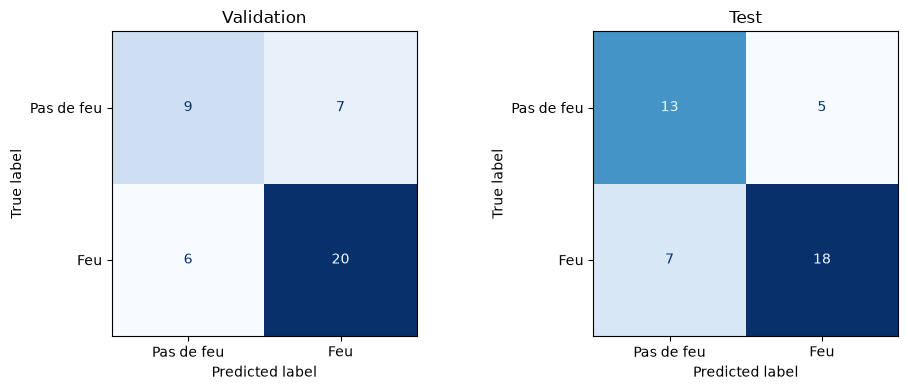

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nom, X, y) in zip(axes, [('Validation', X_val, y_val), ('Test', X_test, y_test)]):
    ConfusionMatrixDisplay.from_estimator(pipe, X, y, display_labels=['Pas de feu', 'Feu'],
                                          cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nom)
plt.tight_layout()
plt.show()

## 6. SHAP : explication des prédictions
SHAP mesure la contribution de chaque variable à la probabilité de feu prédite.
On utilise la même méthode (`Permutation`) pour les 6 modèles afin de pouvoir les comparer.

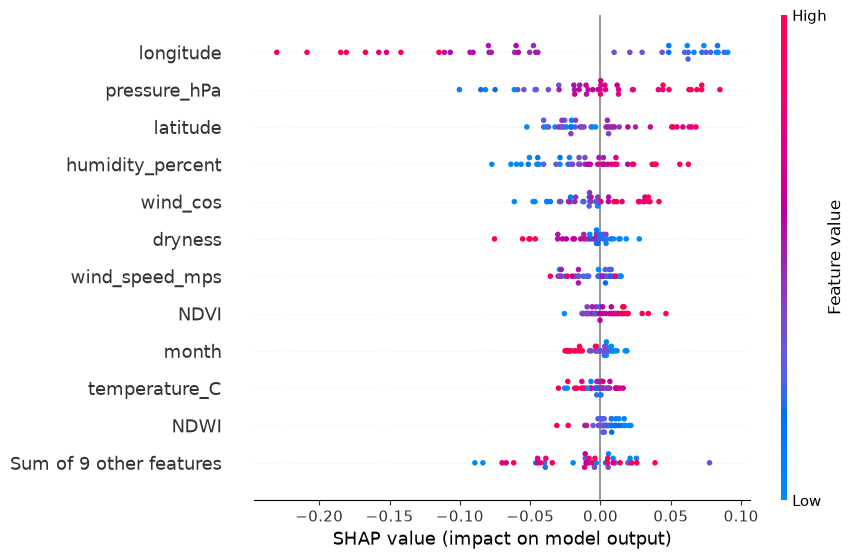

In [7]:
prep, clf = pipe['prep'], pipe['model']
noms = [n.split('__')[1] for n in prep.get_feature_names_out()]
X_train_p = prep.transform(X_train)
X_test_p = prep.transform(X_test)

# Données de référence : 100 lignes du train (valeur par défaut de SHAP)
fond = shap.sample(X_train_p, 100, random_state=0)
explainer = shap.explainers.Permutation(lambda x: clf.predict_proba(x)[:, 1], fond,
                                        feature_names=noms, seed=SEED)
shap_values = explainer(X_test_p, silent=True)

shap.plots.beeswarm(shap_values, max_display=12)

Lecture : un point rouge (valeur élevée) à droite de 0 signifie que cette valeur **augmente** le risque de feu prédit.

## 7. Variables les plus importantes

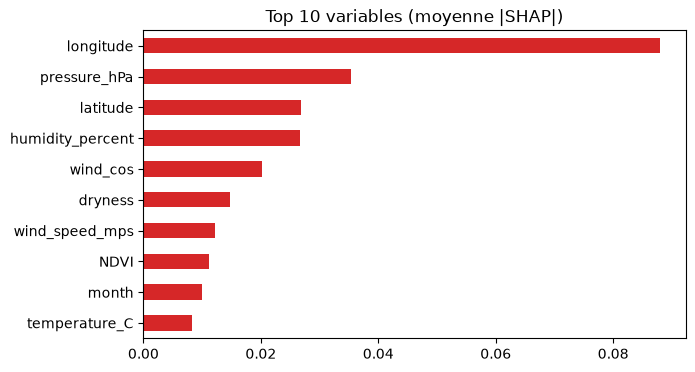

In [8]:
importance = pd.Series(np.abs(shap_values.values).mean(axis=0), index=noms).sort_values()

importance.tail(10).plot.barh(figsize=(7, 4), color='tab:red')
plt.title('Top 10 variables (moyenne |SHAP|)')
plt.show()

## 8. Sauvegarde des résultats (pour le notebook de comparaison)

In [9]:
import os
os.makedirs('resultats', exist_ok=True)

joblib.dump({'nom': 'Extra Trees',
             'pipe': pipe,
             'cv_scores': cv_scores,
             'scores': scores,
             'proba_val': pipe.predict_proba(X_val)[:, 1],
             'proba_test': pipe.predict_proba(X_test)[:, 1],
             'importance': importance}, 'resultats/model_extra_trees.joblib')
print('Sauvegardé dans resultats/model_extra_trees.joblib')

Sauvegardé dans resultats/model_extra_trees.joblib
